LIBRARY

In [1]:
import pandas as pd 
import seaborn as sns
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

FUNCTION

In [2]:
def clean(data):
    df = pd.DataFrame(columns=['Year', 'Age', 'Female', 'Male', 'Total'])

    for i in range(len(data)):
        row = data.iloc[i, 0].split()
        df.loc[len(df)] = row
    
    for column in df.columns:
        if df[column].dtype == "object":
            df[column] = df[column].str.replace(r'[+-.]', '', regex=True)
    
    for column in df.columns:
        df[column] = pd.to_numeric(df[column], errors='coerce') # coerce = jika gagal data jadi nan
        
    df = df.fillna(0)
    
    df = df.drop_duplicates(subset=["Year","Age"]).reset_index(drop = True)
    
    return df

def whittaker_henderson(y, lambda_, d=2):
    n = len(y)
    E = sp.eye(n)
    D = sp.diags([1, -2, 1], [0, 1, 2], shape=(n - 2, n))
    
    # Matriks penalti
    P = lambda_ * D.T @ D
    
    # Menyelesaikan sistem persamaan
    Z = E + P
    z = spla.spsolve(Z, y)
    
    return z

DEATHS

In [3]:
belgium_death = clean(pd.read_csv("Data pembanding/Belgium/Belgium, Deaths (period 1x1),.txt", delimiter = "\t"))
italy_death = clean(pd.read_csv("Data pembanding/Italy/Italy , Deaths (period 1x1).txt", delimiter = "\t"))
japan_death = clean(pd.read_csv("Data pembanding/Japan/Japan, Deaths (period 1x1),.txt", delimiter = "\t"))
ireland_death = clean(pd.read_csv("Data pembanding/Northern Island/Northern Ireland, Deaths (period 1x.txt", delimiter = "\t"))
russia_death = clean(pd.read_csv("Data pembanding/Russia/Russia, Deaths (period 1x1).txt", delimiter = "\t"))
uk_death = clean(pd.read_csv("Data pembanding/UK/United Kingdom, Deaths (period 1x1).txt", delimiter = "\t"))
usa_death = clean(pd.read_csv("Data pembanding/USA/The United States of America, Death.txt", delimiter = "\t"))

POPULATION

In [4]:
belgium_population = clean(pd.read_csv("Data pembanding/Belgium/Belgium, Population size.txt", delimiter = "\t"))
italy_population = clean(pd.read_csv("Data pembanding/Italy/Italy , Population size (abridged).txt", delimiter = "\t"))
japan_population = clean(pd.read_csv("Data pembanding/Japan/Japan, Population size (abridged).txt", delimiter = "\t"))
ireland_population = clean(pd.read_csv("Data pembanding/Northern Island/Northern Ireland, Population size (.txt", delimiter = "\t"))
russia_population = clean(pd.read_csv("Data pembanding/Russia/RussiaPopulation size (abridged).txt", delimiter = "\t"))
uk_population = clean(pd.read_csv("Data pembanding/UK/United Kingdom, Population size (ab.txt", delimiter = "\t"))
usa_population = clean(pd.read_csv("Data pembanding/USA/The United States of America, Popul.txt", delimiter = "\t"))

BELGIUM

In [5]:
backup_bel_death = belgium_death.copy()
backup_bel_death

,Year,Age,Female,Male,Total
0,1841,0,924800.0,1174100.0,2098900.0
1,1841,1,412600.0,415600.0,828200.0
2,1841,2,214700.0,209200.0,423900.0
3,1841,3,124100.0,115500.0,239600.0
4,1841,4,86900.0,81700.0,168600.0
...,...,...,...,...,...
20197,2022,106,1600.0,100.0,1700.0
20198,2022,107,1100.0,0.0,1100.0
20199,2022,108,600.0,0.0,600.0
20200,2022,109,200.0,0.0,200.0


In [6]:
backup_bel_population = belgium_population.copy()
backup_bel_population

,Year,Age,Female,Male,Total
0,1841,0,6043369.0,6232159.0,12275528.0
1,1841,1,5493012.0,5603822.0,11096834.0
2,1841,2,5085658.0,5181085.0,10266743.0
3,1841,3,4832775.0,4881206.0,9713981.0
4,1841,4,4674949.0,4789030.0,9463979.0
...,...,...,...,...,...
20308,2023,106,1933.0,180.0,2113.0
20309,2023,107,990.0,56.0,1046.0
20310,2023,108,771.0,60.0,831.0
20311,2023,109,350.0,0.0,350.0


In [7]:
selisih = len(belgium_population) - len(belgium_death)
backup_bel_population = backup_bel_population[:-selisih].reset_index(drop = True)

WHITE TAKER

In [8]:
# pakai fillna karena 0.0 / 0.0 hasil nan jadi jika nan diberi angka 0

qx_female = (backup_bel_death["Female"] / backup_bel_population["Female"]).fillna(0) 
qx_male = (backup_bel_death["Male"] / backup_bel_population["Male"]).fillna(0) 

qx_head_female = qx_female.head(111)
qx_head_male = qx_male.head(111)
qx_1841_female = qx_head_female[:-8]
qx_1841_male = qx_head_male[:-8]

In [9]:
smoothed_qx_female = whittaker_henderson(qx_1841_female, 1)
smoothed_qx_male = whittaker_henderson(qx_1841_male, 30)

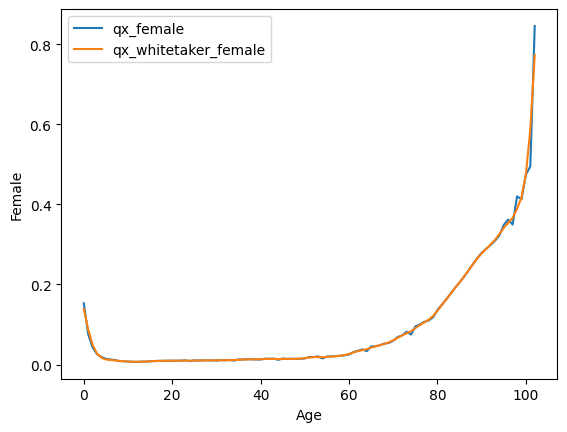

In [10]:
age = backup_bel_death["Age"].head(103)

sns.lineplot(x = age, y = qx_1841_female, label = "qx_female")
sns.lineplot(x = age, y = smoothed_qx_female, label = "qx_whitetaker_female")
plt.legend()

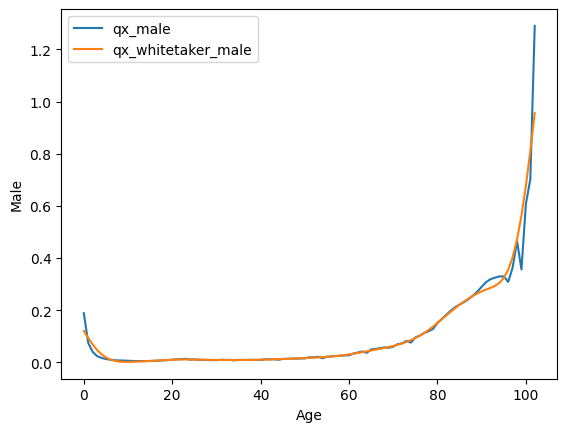

In [11]:
sns.lineplot(x = age, y = qx_1841_male, label = "qx_male")
sns.lineplot(x = age, y = smoothed_qx_male, label = "qx_whitetaker_male")
plt.legend()

In [12]:
backup_bel_death = backup_bel_death[backup_bel_death["Age"] < 103].reset_index(drop=True)
backup_bel_population = backup_bel_population[backup_bel_population["Age"] < 103].reset_index(drop=True)

LAMBDA

In [13]:
dx_female = backup_bel_death["Female"].drop(index=range(7519, 8034)).reset_index(drop=True)
L_female = backup_bel_population["Female"].drop(index=range(7519, 8034)).reset_index(drop=True)
smoothed_double_female = np.tile(smoothed_qx_female, 177)
selisih_smoothed = len(smoothed_double_female) - len(L_female)
t = backup_bel_death["Year"].drop(index=range(7519, 8034)).reset_index(drop=True)
t0 = 1841

numerator = np.log(dx_female / (L_female * smoothed_double_female)) * (t - t0)

index = 103
data = []

for _ in range(103):
    hasil = 0
    for z in range(len(numerator)):
        if z == index:
            hasil += numerator[z]
    data.append(hasil)
    index += 1

numerator = pd.Series(data)
denominator = np.sum((t - t0) ** 2)
lambda_female = - numerator / denominator

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


ALPHA

In [14]:
import numpy as np

tahun = np.arange(0, 178)

alpha = []

for i in range(177): # 0
    numerator = 0
    denominator = 0
    for z in range(len(lambda_female)):
        logika1 = dx_female[z] / (L_female[z] * smoothed_double_female[z])
        logika2 = np.exp(-lambda_female.values[z] * tahun[i])
        logika3 = np.exp(-lambda_female.values[z] * tahun[i]) ** 2
        hasil = logika1 * logika2
        numerator += hasil
        denominator += logika3
    alpha.append(numerator / denominator)

QX

In [15]:
qx = []

for i in range(177):
    for z in range(len(smoothed_qx_female)):
        alpa = alpha[i]
        qxt0 = smoothed_qx_female[z]
        exponen = np.exp(-lambda_female.values[z] * tahun[i])
        hasil = alpa * qxt0 * exponen
        qx.append(hasil)

PIVOT TABEL

In [16]:
tabel = backup_bel_death.drop(index=range(7519, 8034)).reset_index(drop=True)
tabel.drop(columns = ["Female", "Male", "Total"], inplace=True)
tabel["qx"] = qx
tabel.pivot(index='Age', columns='Year', values='qx')

Year,1841,1842,1843,1844,1845,1846,1847,1848,1849,1850,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
Age,,,,,,,,,,,,,,,,,,,,,
0,0.139254,0.139254,0.139254,0.139254,0.139254,0.139254,0.139254,0.139254,0.139254,0.139254,...,0.139254,0.139254,0.139254,0.139254,0.139254,0.139254,0.139254,0.139254,0.139254,0.139254
1,0.087060,0.087060,0.087060,0.087060,0.087060,0.087060,0.087060,0.087060,0.087060,0.087060,...,0.087060,0.087060,0.087060,0.087060,0.087060,0.087060,0.087060,0.087060,0.087060,0.087060
2,0.048877,0.048877,0.048877,0.048877,0.048877,0.048877,0.048877,0.048877,0.048877,0.048877,...,0.048877,0.048877,0.048877,0.048877,0.048877,0.048877,0.048877,0.048877,0.048877,0.048877
3,0.026888,0.026888,0.026888,0.026888,0.026888,0.026888,0.026888,0.026888,0.026888,0.026888,...,0.026888,0.026888,0.026888,0.026888,0.026888,0.026888,0.026888,0.026888,0.026888,0.026888
4,0.016683,0.016683,0.016683,0.016683,0.016683,0.016683,0.016683,0.016683,0.016683,0.016683,...,0.016683,0.016683,0.016683,0.016683,0.016683,0.016683,0.016683,0.016683,0.016683,0.016683
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,0.389640,0.389640,0.389640,0.389640,0.389640,0.389640,0.389640,0.389640,0.389640,0.389640,...,0.389640,0.389640,0.389640,0.389640,0.389640,0.389640,0.389640,0.389640,0.389640,0.389640
99,0.417688,0.417688,0.417688,0.417688,0.417688,0.417688,0.417688,0.417688,0.417688,0.417688,...,0.417688,0.417688,0.417688,0.417688,0.417688,0.417688,0.417688,0.417688,0.417688,0.417688
100,0.476882,0.476882,0.476882,0.476882,0.476882,0.476882,0.476882,0.476882,0.476882,0.476882,...,0.476882,0.476882,0.476882,0.476882,0.476882,0.476882,0.476882,0.476882,0.476882,0.476882


In [17]:
dx_male = backup_bel_death[["Male"]]
L_male = backup_bel_population[["Male"]]

# smoothed_qx_female
# smoothed_qx_male

# log(death(female,male) / (populasi(female, male) * qx(1841)))

ITALY

In [18]:
italy_death

,Year,Age,Female,Male,Total
0,1872,0,10538910,12249948,22788858
1,1872,1,3754138,3899743,7653881
2,1872,2,2531744,2631324,5163068
3,1872,3,1623895,1686739,3310634
4,1872,4,1030589,1065991,2096580
...,...,...,...,...,...
16645,2021,106,17100,1200,18300
16646,2021,107,8900,1300,10200
16647,2021,108,4100,1000,5100
16648,2021,109,1800,300,2100


In [19]:
italy_population

,Year,Age,Female,Male,Total
0,1872,0,36603052,37659695,74262747
1,1872,1,23911377,24838732,48750109
2,1872,2,32160565,33330786,65491351
3,1872,3,30017087,31045319,61062406
4,1872,4,29849952,30202658,60052610
...,...,...,...,...,...
16756,2022,106,23476,2923,26399
16757,2022,107,12754,1232,13986
16758,2022,108,5724,752,6476
16759,2022,109,2388,384,2772


JAPAN

In [20]:
japan_death

,Year,Age,Female,Male,Total
0,1947,0,9392318,11181853,20574171
1,1947,1,2771928,2967179,5739107
2,1947,2,1469606,1496264,2965870
3,1947,3,1106888,1140860,2247748
4,1947,4,670444,729946,1400390
...,...,...,...,...,...
8431,2022,106,89710,9804,99514
8432,2022,107,45305,5402,50707
8433,2022,108,28003,2201,30204
8434,2022,109,11402,1100,12502


In [21]:
japan_population

,Year,Age,Female,Male,Total
0,1947,0,90951322,94715542,185666864
1,1947,1,81183531,83178064,164361595
2,1947,2,95147884,97113276,192261160
3,1947,3,97110514,99241018,196351532
4,1947,4,98173207,100729582,198902789
...,...,...,...,...,...
8542,2023,106,139723,12175,151898
8543,2023,107,74943,5829,80772
8544,2023,108,39618,3015,42633
8545,2023,109,18835,1144,19979


IRELAND

In [22]:
ireland_death

,Year,Age,Female,Male,Total
0,1922,0,100300,127700,228000
1,1922,1,27000,30200,57200
2,1922,2,12100,14000,26100
3,1922,3,6400,5700,12100
4,1922,4,4900,4700,9600
...,...,...,...,...,...
11095,2021,106,0,0,0
11096,2021,107,100,0,100
11097,2021,108,0,0,0
11098,2021,109,0,0,0


In [23]:
ireland_population

,Year,Age,Female,Male,Total
0,1922,0,1399921,1436775,2836696
1,1922,1,1346866,1388744,2735610
2,1922,2,1249681,1296765,2546446
3,1922,3,1080419,1112145,2192564
4,1922,4,1050063,1064079,2114142
...,...,...,...,...,...
11206,2022,106,296,0,296
11207,2022,107,85,0,85
11208,2022,108,0,0,0
11209,2022,109,0,0,0


RUSSIA

In [24]:
russia_death

,Year,Age,Female,Male,Total
0,1959,0,5047952,6533588,11581540
1,1959,1,836990,927023,1764013
2,1959,2,324490,363205,687695
3,1959,3,209523,243738,453261
4,1959,4,161894,215322,377216
...,...,...,...,...,...
6211,2014,106,4763,875,5638
6212,2014,107,2655,520,3175
6213,2014,108,1385,285,1670
6214,2014,109,718,155,873


In [25]:
russia_population

,Year,Age,Female,Male,Total
0,1959,0,135478100,141026400,276504500
1,1959,1,132783400,138047800,270831200
2,1959,2,128534000,133506400,262040400
3,1959,3,131388500,136511600,267900100
4,1959,4,133933300,138709900,272643200
...,...,...,...,...,...
6322,2015,106,10497,2389,12886
6323,2015,107,6222,1485,7707
6324,2015,108,3295,784,4079
6325,2015,109,1711,378,2089


UK

In [26]:
uk_death

,Year,Age,Female,Male,Total
0,1922,0,3130300,4276219,7406519
1,1922,1,1130100,1264607,2394707
2,1922,2,519200,569903,1089103
3,1922,3,218200,232501,450701
4,1922,4,144300,142701,287001
...,...,...,...,...,...
11095,2021,106,10303,1675,11978
11096,2021,107,5290,749,6039
11097,2021,108,2545,340,2885
11098,2021,109,1359,159,1518


In [27]:
uk_population

,Year,Age,Female,Male,Total
0,1922,0,45859468,47294002,93153470
1,1922,1,46063340,47367804,93431144
2,1922,2,40132618,41226859,81359477
3,1922,3,31983348,32574767,64558115
4,1922,4,33461538,33959287,67420825
...,...,...,...,...,...
11206,2022,106,14715,2014,16729
11207,2022,107,7486,927,8413
11208,2022,108,3495,344,3839
11209,2022,109,1474,102,1576


USA

In [28]:
usa_death

,Year,Age,Female,Male,Total
0,1933,0,5261577,6843811,12105388
1,1933,1,891713,1032916,1924629
2,1933,2,433692,514005,947697
3,1933,3,316159,375988,692147
4,1933,4,249384,293259,542643
...,...,...,...,...,...
9985,2022,106,58100,9200,67300
9986,2022,107,32500,4800,37300
9987,2022,108,17300,1700,19000
9988,2022,109,9300,600,9900


In [29]:
usa_population

,Year,Age,Female,Male,Total
0,1933,0,98447226,101536155,199983381
1,1933,1,104049602,106408829,210458431
2,1933,2,109304381,111752714,221057095
3,1933,3,110799431,113504659,224304090
4,1933,4,113062443,117951362,231013805
...,...,...,...,...,...
10096,2023,106,100266,14272,114538
10097,2023,107,54822,6915,61737
10098,2023,108,28458,3406,31864
10099,2023,109,13987,1633,15620
